<a href="https://colab.research.google.com/github/pn18916-jpg/Python-Projects/blob/main/Spotify_Pasupathy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
spotify = pd.read_csv("spotify.csv")
spotify.head()

,track_name,artists,popularity,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,Neon Lights,Eli Gray,16,0.662,0.122,-13.60,0.091,0.449,0.341,0.540,94.2
1,Midnight City,Maya Quinn,31,0.372,0.289,-5.78,0.076,0.284,0.197,0.645,155.0
2,Broken Night,Kai Stone,45,0.372,0.659,-12.16,0.193,0.658,0.065,0.809,155.4
3,Golden Dream,Theo Cross,57,0.319,0.930,-3.98,0.151,0.500,0.169,0.509,80.0
4,Wild Sun,Maya Fox,44,0.784,0.472,-16.98,0.155,0.519,0.351,0.908,166.3


In [ ]:
features = [
    "danceability",
    "energy",
    "loudness",
    "acousticness",
    "valence",
    "tempo"
]

spotify_model = spotify[features + ["popularity"]].copy()

In [ ]:
spotify_model["popular"] = (
    spotify_model["popularity"] >= 60
).astype(int)

In [ ]:
spotify_model[["popularity", "popular"]].head(10)

,popularity,popular
0,16,0
1,31,0
2,45,0
3,57,0
4,44,0
5,68,1
6,27,0
7,21,0
8,68,1
9,23,0


In [ ]:
spotify_model["popular"].value_counts()

,count
popular,
0,389
1,111


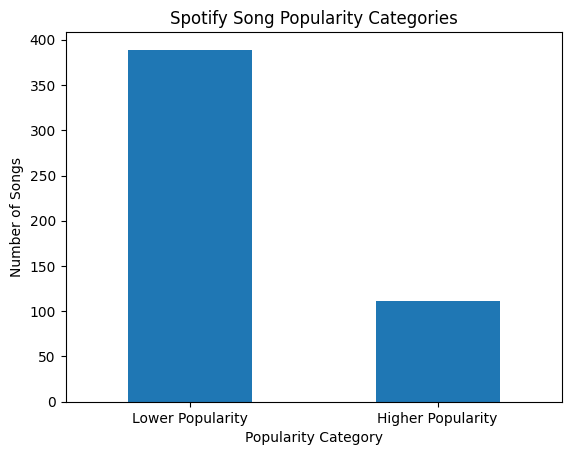

In [ ]:
spotify_model["popular"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Spotify Song Popularity Categories")
plt.xlabel("Popularity Category")
plt.ylabel("Number of Songs")
plt.xticks(
    ticks=[0, 1],
    labels=["Lower Popularity", "Higher Popularity"],
    rotation=0
)
plt.show()

In [ ]:
spotify_model.groupby("popular")[features].mean()

,danceability,energy,loudness,acousticness,valence,tempo
popular,,,,,,
0,0.526332,0.534262,-10.643470,0.405003,0.495573,123.986375
1,0.647036,0.623495,-7.876937,0.353009,0.533234,130.667568


In [ ]:
X = spotify_model[features]
y = spotify_model["popular"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 400
Testing rows: 100


In [ ]:
model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, random_state=42)

In [ ]:
predictions = model.predict(X_test)

In [ ]:
predictions[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predictions
})

comparison.head(10)

,Actual,Predicted
393,0,0
241,0,1
306,0,0
386,0,0
134,0,0
193,0,0
68,0,0
28,0,0
107,0,0
186,1,0


In [ ]:
accuracy = accuracy_score(y_test, predictions)

print("Model accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Model accuracy: 0.73
Accuracy percentage: 73.0 %


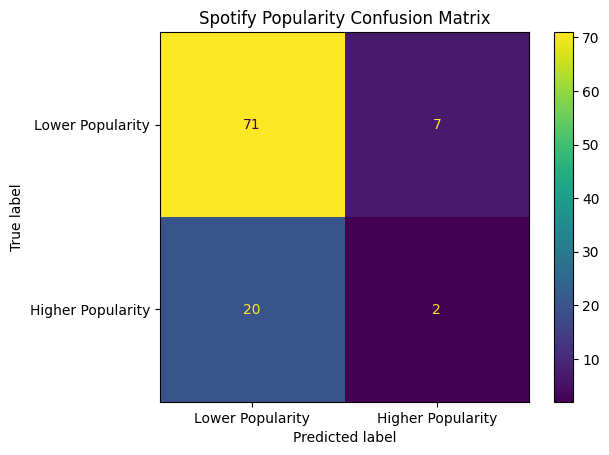

In [ ]:
matrix = confusion_matrix(y_test, predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=["Lower Popularity", "Higher Popularity"]
)

display.plot()
plt.title("Spotify Popularity Confusion Matrix")
plt.show()

In [ ]:
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

,Feature,Importance
2,loudness,0.449816
0,danceability,0.248263
1,energy,0.135809
5,tempo,0.093173
3,acousticness,0.041063
4,valence,0.031878


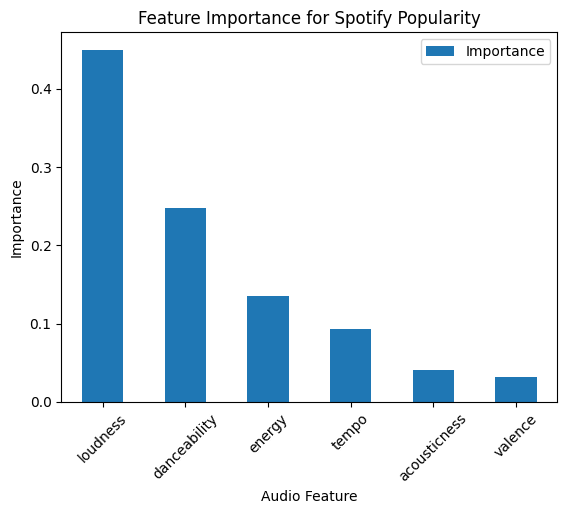

In [ ]:
importance.plot(
    x="Feature",
    y="Importance",
    kind="bar"
)

plt.title("Feature Importance for Spotify Popularity")
plt.xlabel("Audio Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

In [ ]:
new_song = pd.DataFrame({
    "danceability": [0.70],
    "energy": [0.80],
    "loudness": [-5.0],
    "acousticness": [0.10],
    "valence": [0.50],
    "tempo": [120.0]
})

new_prediction = model.predict(new_song)

if new_prediction[0] == 1:
    print("The model predicts higher popularity.")
else:
    print("The model predicts lower popularity.")

The model predicts lower popularity.


In [ ]:
new_var = 6
new_var0 = 42
improved_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

improved_model.fit(X_train, y_train)

improved_predictions = improved_model.predict(X_test)

improved_accuracy = accuracy_score(
    y_test,
    improved_predictions
)

print(
    "New accuracy:",
    round(improved_accuracy * 100, 2),
    "%"
)

New accuracy: 74.0 %
